# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
from pathlib import Path
import io,zipfile,urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display,Markdown

## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [2]:
file = Path('house_price_regression_dataset.csv')
if not file.exists() and not (Path('Джерельні файли') / file).exists():
    from google.colab import files
    files.upload()
if not file.exists():
    file = Path('Джерельні файли') / file
df = pd.read_csv(file)
print('Локальний файл:', df.shape)
display(df.head())

Локальний файл: (1000, 8)


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [3]:
url = 'https://www.kaggle.com/api/v1/datasets/download/prokshitha/home-value-insights?datasetVersionNumber=1'
archive = urllib.request.urlopen(url, timeout=90).read()
with zipfile.ZipFile(io.BytesIO(archive)) as z:
    csv_name = next(name for name in z.namelist() if name.endswith('.csv'))
    df_kaggle = pd.read_csv(z.open(csv_name))
print('Kaggle:', df_kaggle.shape)
print('Дані двох способів збігаються:', df.equals(df_kaggle))

Kaggle: (1000, 8)
Дані двох способів збігаються: True


## 3. Опис ознак датасету

- **Square_Footage** : загальна житлова площа будинку.
- **Num_Bedrooms** : кількість спалень.
- **Num_Bathrooms** : кількість ванних кімнат.
- **Year_Built** : рік побудови будинку.
- **Lot_Size** : розмір земельної ділянки.
- **Garage_Size** : розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** : оцінка якості району.
- **House_Price** : ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [4]:
display(df.head())
df.info()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [5]:
print('Дублікати:', df.duplicated().sum())

Дублікати: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [6]:
display(df.isna().sum())

Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64

### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [7]:
display(df.describe())

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [8]:
display(df['Neighborhood_Quality'].value_counts().sort_index())

Neighborhood_Quality
1      91
2     105
3      85
4      99
5     109
6     101
7     102
8      97
9      88
10    123
Name: count, dtype: int64

### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

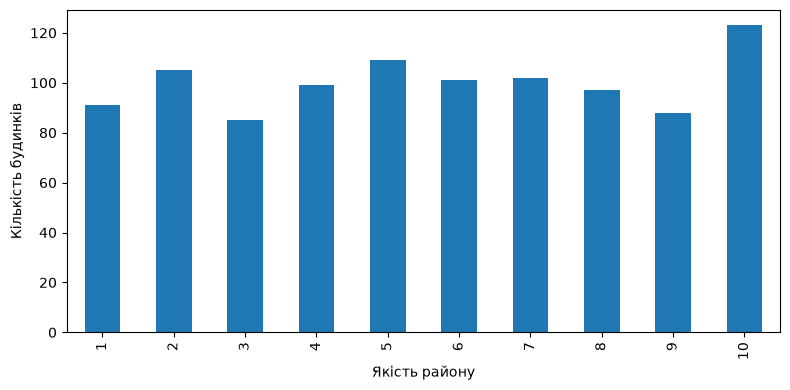

In [9]:
df['Neighborhood_Quality'].value_counts().sort_index().plot.bar(figsize=(8, 4))
plt.xlabel('Якість району')
plt.ylabel('Кількість будинків')
plt.tight_layout()
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

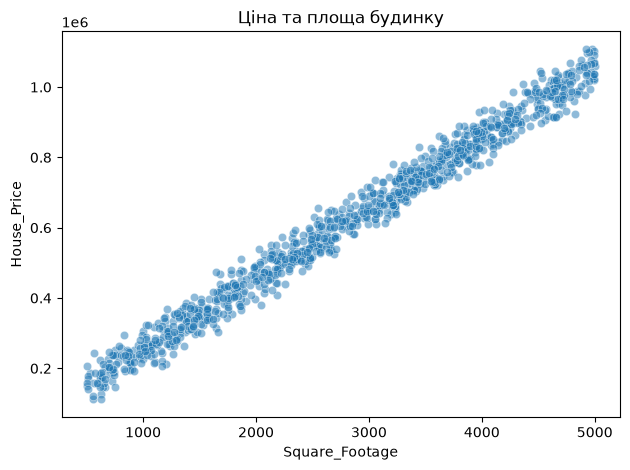

In [10]:
sns.scatterplot(data=df, x='Square_Footage', y='House_Price', alpha=0.5)
plt.title('Ціна та площа будинку')
plt.tight_layout()
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

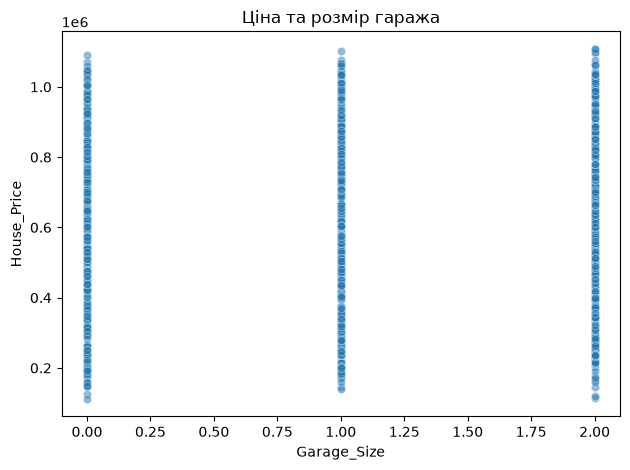

In [11]:
sns.scatterplot(data=df, x='Garage_Size', y='House_Price', alpha=0.5)
plt.title('Ціна та розмір гаража')
plt.tight_layout()
plt.show()

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

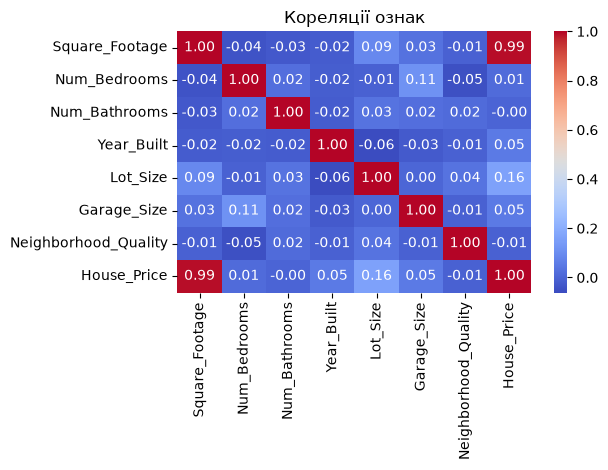

In [12]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Кореляції ознак')
plt.tight_layout()
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [13]:
display(corr['House_Price'].drop('House_Price').sort_values(ascending=False))

Square_Footage          0.991261
Lot_Size                0.160412
Garage_Size             0.052133
Year_Built              0.051967
Num_Bedrooms            0.014633
Num_Bathrooms          -0.001862
Neighborhood_Quality   -0.007770
Name: House_Price, dtype: float64

## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [14]:
from sklearn.model_selection import train_test_split,GridSearchCV,KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [15]:
X = df.drop(columns='House_Price')
y = df['House_Price']
print(X.shape, y.shape)

(1000, 7) (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (800, 7) Test: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [17]:
models = {
    'Linear Regression': Pipeline([('scale',StandardScaler()),('model',LinearRegression())]),
    'Ridge': Pipeline([('scale',StandardScaler()),('model',Ridge(alpha=1))]),
    'Lasso': Pipeline([('scale',StandardScaler()),('model',Lasso(alpha=1,max_iter=20000))]),
    'Random Forest': RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=2),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}
print(list(models))

['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting']


### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [18]:
def metrics(actual,pred):
    return {'R²':r2_score(actual,pred),'MAE':mean_absolute_error(actual,pred),'MSE':mean_squared_error(actual,pred)}
rows=[]
predictions={}
for name,model in models.items():
    model.fit(X_train,y_train)
    predictions[name]=model.predict(X_test)
    rows.append({'Модель':name,**metrics(y_test,predictions[name])})
results=pd.DataFrame(rows).set_index('Модель').sort_values('R²',ascending=False)
display(results)

,R²,MAE,MSE
Модель,,,
Linear Regression,0.998426,8174.583600,1.014348e+08
Lasso,0.998426,8174.748374,1.014366e+08
Ridge,0.998410,8241.586911,1.024810e+08
Gradient Boosting,0.996510,12305.217615,2.249656e+08
Random Forest,0.993886,16114.289644,3.941317e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

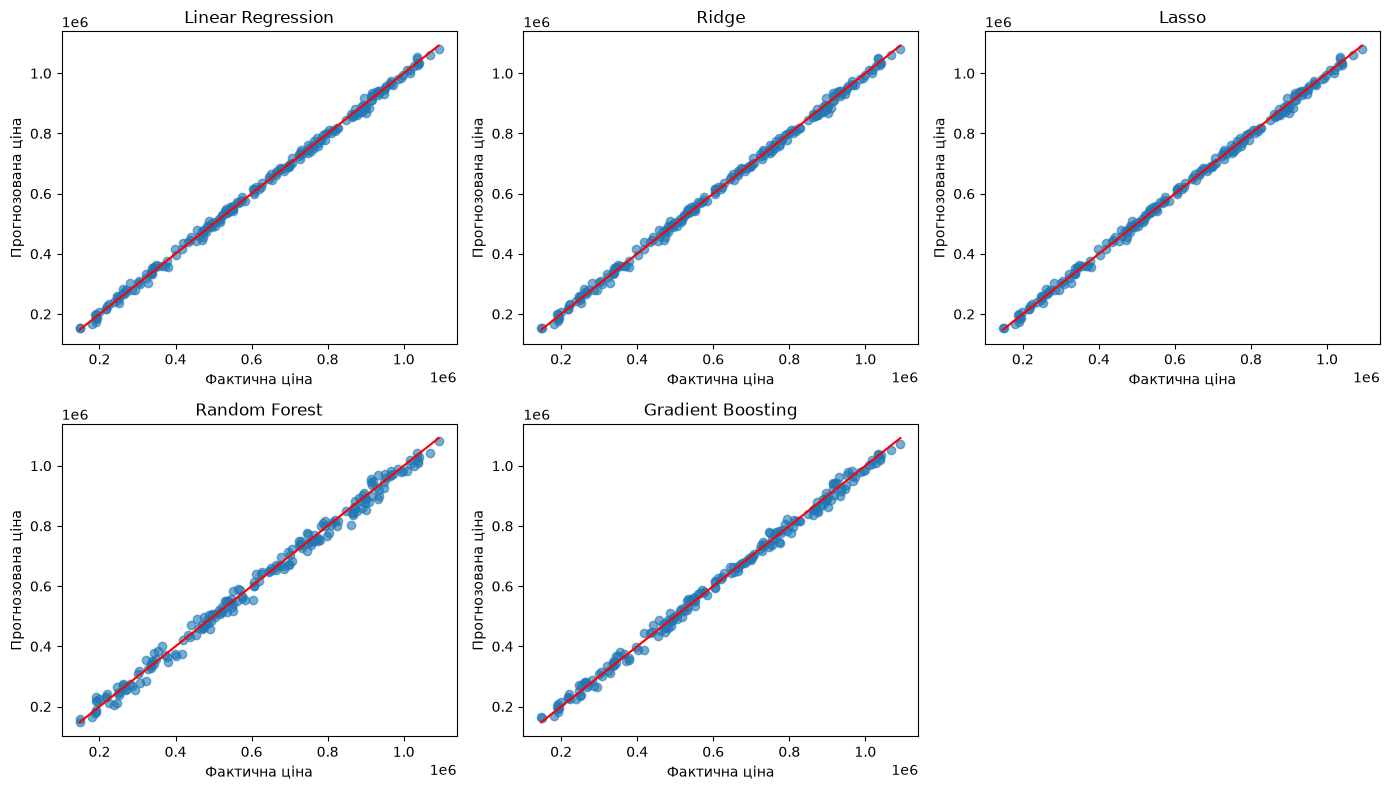

In [19]:
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,(name,pred) in zip(axes.flat,predictions.items()):
    ax.scatter(y_test,pred,alpha=0.6)
    ax.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],color='red')
    ax.set(title=name,xlabel='Фактична ціна',ylabel='Прогнозована ціна')
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [20]:
grid={'n_estimators':[100,200],'max_features':[1.0,'sqrt'],'max_depth':[None,12],'min_samples_split':[2,5]}
cv=KFold(3,shuffle=True,random_state=42)
search=GridSearchCV(RandomForestRegressor(random_state=42,n_jobs=1),grid,cv=cv,scoring='r2',n_jobs=2)
search.fit(X_train,y_train)
print('Найкращі параметри:',search.best_params_)
print('CV R²:',search.best_score_)

Найкращі параметри: {'max_depth': 12, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 200}
CV R²: 0.9920102417458075


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [21]:
optimized=RandomForestRegressor(**search.best_params_,random_state=42,n_jobs=2)
optimized.fit(X_train,y_train)
optimized_metrics=metrics(y_test,optimized.predict(X_test))
display(pd.Series(optimized_metrics))

R²     9.940575e-01
MAE    1.594774e+04
MSE    3.830485e+08
dtype: float64

### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [22]:
forest_compare=pd.DataFrame([results.loc['Random Forest'].to_dict(),optimized_metrics],index=['Базова','Оптимізована'])
display(forest_compare)

,R²,MAE,MSE
Базова,0.993886,16114.289644,3.941317e+08
Оптимізована,0.994057,15947.741940,3.830485e+08


### Аналіз оптимізації
Результат підбору оцінюється за таблицею вище. Параметри вибрано за кросвалідацією на train; покращення на test не гарантоване. Остаточні числові результати наведено у висновку.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [23]:
linear_table=pd.DataFrame({'Фактична ціна':y_test,'Прогнозована ціна':predictions['Linear Regression']})
linear_table['Похибка, %']=(linear_table['Прогнозована ціна']-linear_table['Фактична ціна'])/linear_table['Фактична ціна']*100
display(linear_table.sample(10,random_state=42))

,Фактична ціна,Прогнозована ціна,"Похибка, %"
436,1.068538e+06,1.059729e+06,-0.824406
899,1.943537e+05,1.878686e+05,-3.336793
346,2.702306e+05,2.797158e+05,3.510031
60,9.860069e+05,9.819493e+05,-0.411517
867,9.533397e+05,9.573829e+05,0.424111
432,9.145557e+05,9.097643e+05,-0.523912
543,7.461677e+05,7.424691e+05,-0.495678
361,6.467663e+05,6.544456e+05,1.187332
486,5.233231e+05,5.246054e+05,0.245045
277,1.008539e+06,1.011344e+06,0.278073


## Загальний висновок

Побудовано Linear Regression, Ridge, Lasso, Random Forest і Gradient Boosting. Найкращий тестовий R² серед початкових моделей має **Linear Regression**: 0.9984, MAE становить 8174.58, MSE становить 101434798.51. Після підбору параметрів Random Forest зміна R² дорівнює +0.0002; MAE змінюється з 16114.29 до 15947.74, MSE з 394131747.45 до 383048494.46. Оптимізований варіант доцільно залишити для цього експерименту. Основний лінійний зв’язок ціни спостерігається з площею будинку. Якість прогнозу також залежить від кількості кімнат, розташування, стану будинку та повноти даних; причинний вплив за кореляцією встановити не можна.